> **Bản PyTorch** của `examples/3. CNN + LSTM/MNIST_CNN_LSTM.ipynb` (Keras). Người chuyển: TV1 – Đoàn Trung Kiên.
>
> **Thay đổi so với bản Keras**

> - `keras.datasets.mnist` → `torchvision.datasets.MNIST` (tải về `../data`).
> - Chuỗi ảnh Keras dạng `(N, 8, 28, 28, 1)` (channels-last) → PyTorch `(N, 8, 1, 28, 28)` (channels-first, `float32`).
> - `TimeDistributed(Conv2D / MaxPooling2D / Dropout / Flatten)` không có sẵn trong PyTorch → gộp chiều thời gian vào batch `(B * T, 1, 28, 28)` đưa qua 3 khối CNN giống `1_MNIST_CNN` (`Flatten` ra `256 * 3 * 3 = 2304`), sau đó tách lại `(B, T, 2304)`.
> - `LSTM(128, return_sequences=True)` + `LSTM(128, return_sequences=False)` → hai lớp `nn.LSTM(..., hidden_size=128, batch_first=True)`, lấy bước thời gian cuối `out[:, -1, :]` → `nn.Dropout(0.22)` → `nn.Linear(128, 1)` (đầu ra tuyến tính hồi quy tổng chữ số). Lưu ý: mỗi lớp `nn.LSTM` của PyTorch có cả `bias_ih` và `bias_hh` nên nhiều hơn Keras `4 * 128 = 512` tham số/lớp (tổng tham số `1,748,097` so với `1,747,073` của Keras).
> - `loss='mean_absolute_error'` + `SGD(lr=0.01)` → `nn.L1Loss()` + `torch.optim.SGD(lr=0.01)`; `init_like_keras` khởi tạo `xavier_uniform_` cho Conv/Linear/LSTM `weight_ih`, `orthogonal_` cho LSTM `weight_hh` và `forget_bias = 1` giống mặc định Keras.
> - Bỏ `SVG(model_to_dot(...))` → in bảng `summary`; các hàm `summary`, `fit`, `evaluate`, `predict`, `plot_history`, `make_loader` chép từ khuôn vào trực tiếp trong notebook.

# Overview
- MNIST dataset
  + Goal: estimating summation of handwritten digit images
  + Input: a set of 28x28 images
  + Output: summation of given handwritten digit images
- Defining an CNN+LSTM for MNIST dataset
- Training and evaluating an CNN+LSTM

# Import libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device,
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Chép từ khuôn `MNIST_MLP` / `1_MNIST_CNN` và điều chỉnh cho bài toán hồi quy MAE (`nn.L1Loss`). Mỗi notebook tự chứa các hàm dưới đây, không phụ thuộc file code ngoài.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            def _hook(mod, inp, out, name=name):
                out_t = out[0] if isinstance(out, tuple) else out
                rows.append((name, type(mod).__name__, tuple(out_t.shape), sum(p.numel() for p in mod.parameters())))
            hooks.append(m.register_forward_hook(_hook))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Khởi tạo giống mặc định Keras cho Conv2d/Linear (glorot_uniform, bias=0)
    và LSTM (kernel glorot_uniform, recurrent orthogonal, unit_forget_bias=1.0)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LSTM):
            for name, param in m.named_parameters():
                if 'weight_ih' in name:
                    nn.init.xavier_uniform_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
                elif 'bias_ih' in name:
                    nn.init.zeros_(param)
                    h = m.hidden_size
                    param.data[h:2 * h].fill_(1.0)   # unit_forget_bias=True trong Keras
                elif 'bias_hh' in name:
                    nn.init.zeros_(param)


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader cho bài toán hồi quy (dùng from_numpy tránh nhân đôi RAM)."""
    x_arr = np.ascontiguousarray(x, dtype=np.float32)
    y_arr = np.ascontiguousarray(y, dtype=np.float32)
    ds = TensorDataset(torch.from_numpy(x_arr), torch.from_numpy(y_arr))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện hồi quy; trả về MAE trung bình trên tập train."""
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        n += len(y)
    return total_loss / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về MAE trung bình trên cả tập."""
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            total_loss += loss_fn(pred, y).item() * len(y)
            n += len(y)
    return total_loss / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in loss/val_loss mỗi epoch, trả về history."""
    history = {'loss': [], 'val_loss': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss = evaluate(model, val_loader, loss_fn)
        history['loss'].append(loss)
        history['val_loss'].append(val_loss)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - val_loss: {val_loss:.4f}')
    return history


def predict(model, x, batch_size=256):
    """Tương đương model.predict(): trả về dự đoán tổng chữ số dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(model(xb).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ đường hội tụ MAE (loss & val_loss) theo epoch."""
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(history['loss']) + 1), history['loss'], label='train')
    plt.plot(range(1, len(history['val_loss']) + 1), history['val_loss'], label='validation')
    plt.xlabel('epoch'); plt.ylabel('MAE loss'); plt.title('CNN + LSTM MAE Loss'); plt.legend(); plt.grid(alpha=.3)
    plt.show()

# (1) Data

In [3]:
# the data, split between train and test sets (giống mnist.load_data())
train_set = datasets.MNIST(root='../data', train=True, download=True)
test_set = datasets.MNIST(root='../data', train=False, download=True)
X_train_raw, y_train_temp = train_set.data.numpy(), train_set.targets.numpy()
X_test_raw, y_test_temp = test_set.data.numpy(), test_set.targets.numpy()

# basic image processing
X_train_raw = X_train_raw.astype('float32') / 255.0
X_test_raw = X_test_raw.astype('float32') / 255.0

print('X_train_raw shape:', X_train_raw.shape)
print(X_train_raw.shape[0], 'train samples')
print(X_test_raw.shape[0], 'test samples')

X_train_raw shape: (60000, 28, 28)
60000 train samples
10000 test samples


## Original data
- Input: 28x28 image
- Output: label (0, 1,..., 9)

## Data preprocessing
- Read images from MNIST
- Compute their summation

## New data
- Input: eight 28x28 images — PyTorch channels-first `(N, 8, 1, 28, 28)`
- Output: summation of up to eight input images

In [4]:
n_train = X_train_raw.shape[0]
y_train = np.zeros(n_train, dtype=np.float32)

n_test = X_test_raw.shape[0]
y_test = np.zeros(n_test, dtype=np.float32)

np.random.seed(2018)
maxToAdd = 8
size = 28

# Keras: (n_train, 8, 28, 28, 1) -> PyTorch channels-first: (n_train, 8, 1, 28, 28)
x_train = np.zeros((n_train, maxToAdd, 1, size, size), dtype=np.float32)
for i in range(n_train):
    numToAdd = int(np.ceil(np.random.rand() * maxToAdd))
    indices = np.random.choice(n_train, size=numToAdd)
    x_train[i, 0:numToAdd, 0, :, :] = X_train_raw[indices]
    y_train[i] = np.sum(y_train_temp[indices])

print('x_train shape: ', x_train.shape)
print('y_train shape: ', y_train.shape)

x_test = np.zeros((n_test, maxToAdd, 1, size, size), dtype=np.float32)
for i in range(n_test):
    numToAdd = int(np.ceil(np.random.rand() * maxToAdd))
    indices = np.random.choice(n_test, size=numToAdd)
    x_test[i, 0:numToAdd, 0, :, :] = X_test_raw[indices]
    y_test[i] = np.sum(y_test_temp[indices])

print('x_test shape: ', x_test.shape)
print('y_test shape: ', y_test.shape)

x_train shape:  (60000, 8, 1, 28, 28)
y_train shape:  (60000,)


x_test shape:  (10000, 8, 1, 28, 28)
y_test shape:  (10000,)


# (2) Declare model

In [5]:
class MnistCNNLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        # CNN trích đặc trưng cho từng ảnh (thay cho TimeDistributed bằng gộp chiều B*T)
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2)
        self.conv_dropout1 = nn.Dropout(0.2)

        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)
        self.conv_dropout2 = nn.Dropout(0.2)

        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2)
        self.conv_dropout3 = nn.Dropout(0.2)

        self.flatten = nn.Flatten()

        # 2 tầng LSTM: sau 3 lần pool 28 -> 14 -> 7 -> 3 nên chiều vào LSTM là 256 * 3 * 3 = 2304
        self.lstm1 = nn.LSTM(input_size=256 * 3 * 3, hidden_size=128, batch_first=True)
        self.lstm2 = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.lstm_dropout = nn.Dropout(0.22)
        self.fc = nn.Linear(128, 1)    # Đầu ra tuyến tính dự đoán tổng chữ số

    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.reshape(b * t, c, h, w)   # Gộp chiều thời gian vào batch (thay TimeDistributed)

        x = self.conv_dropout1(self.pool1(torch.relu(self.conv1(x))))
        x = self.conv_dropout2(self.pool2(torch.relu(self.conv2(x))))
        x = self.conv_dropout3(self.pool3(torch.relu(self.conv3(x))))
        x = self.flatten(x)             # (B * T, 2304)

        x = x.reshape(b, t, -1)         # Tách lại chiều thời gian (B, T, 2304)
        x, _ = self.lstm1(x)            # return_sequences=True -> (B, T, 128)
        x, _ = self.lstm2(x)            # lấy bước thời gian cuối -> return_sequences=False
        x = self.lstm_dropout(x[:, -1, :])
        return self.fc(x).squeeze(-1)


np.random.seed(SEED)
torch.manual_seed(SEED)
model = MnistCNNLSTM().to(device)
init_like_keras(model)
summary(model, (maxToAdd, 1, 28, 28))   # Keras: 1,747,073 (+1,024 do bias_hh của 2 lớp nn.LSTM = 1,748,097)

Layer (type)                        Output Shape               Param #
conv1 (Conv2d)                      (None, 64, 28, 28)             640
pool1 (MaxPool2d)                   (None, 64, 14, 14)               0
conv_dropout1 (Dropout)             (None, 64, 14, 14)               0
conv2 (Conv2d)                      (None, 128, 14, 14)         73,856
pool2 (MaxPool2d)                   (None, 128, 7, 7)                0
conv_dropout2 (Dropout)             (None, 128, 7, 7)                0
conv3 (Conv2d)                      (None, 256, 7, 7)          295,168
pool3 (MaxPool2d)                   (None, 256, 3, 3)                0
conv_dropout3 (Dropout)             (None, 256, 3, 3)                0
flatten (Flatten)                   (None, 2304)                     0
lstm1 (LSTM)                        (None, 8, 128)           1,246,208
lstm2 (LSTM)                        (None, 8, 128)             132,096
lstm_dropout (Dropout)              (None, 128)                      0
fc (Li

# (3) Train defined model
- Note that the training history including loss will be saved in `'history'` variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [6]:
loss_fn = nn.L1Loss()     # tương đương loss='mean_absolute_error'
lr = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

batch_size = 128
epochs = 30
train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/30 - 38.7s - loss: 6.7340 - val_loss: 4.1093


Epoch 2/30 - 38.6s - loss: 3.7691 - val_loss: 3.0975


Epoch 3/30 - 38.8s - loss: 3.0312 - val_loss: 2.3998


Epoch 4/30 - 38.9s - loss: 2.5246 - val_loss: 1.9588


Epoch 5/30 - 38.9s - loss: 2.1050 - val_loss: 1.7795


Epoch 6/30 - 39.0s - loss: 1.8624 - val_loss: 1.8965


... (20 outputs left out)

Epoch 27/30 - 39.4s - loss: 0.9701 - val_loss: 0.6494


Epoch 28/30 - 39.4s - loss: 0.9597 - val_loss: 0.6226


Epoch 29/30 - 39.4s - loss: 0.9440 - val_loss: 0.6231


Epoch 30/30 - 39.4s - loss: 0.9395 - val_loss: 0.7033
> training time is 19.6036 minutes


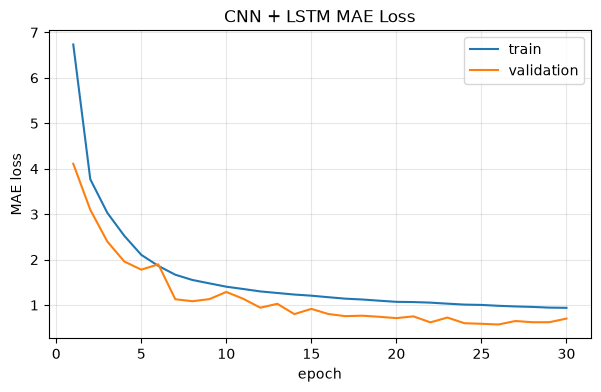

In [7]:
plot_history(history)

### Training time
- Bản Keras gốc (GTX 1080): 26.6267 phút cho 30 epoch, test MAE 0.6502 (Core i7: ~808 phút)
- Bản PyTorch: xem kết quả ô trên (NVIDIA GeForce RTX 3050 Laptop GPU)

# (4) Evaluate trained model

In [8]:
score = evaluate(model, test_loader, loss_fn)
print('Mean absolute error of testing set:', score)

Mean absolute error of testing set: 0.7033117645263672


> actual summation = 31
> estimated summation = 31.801


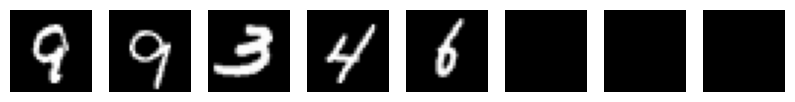

In [9]:
# select a test image sequence randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]

plt.figure(figsize=(10, 5))
for indx in range(maxToAdd):
    plt.subplot(1, maxToAdd, indx + 1)
    test_img = x_test[random_test_index, indx, 0, :, :]   # PyTorch: kênh nằm ở chiều 0
    plt.axis('off')
    plt.imshow(test_img, cmap='gray')

# estimate summation of testing images
est_sum = predict(model, np.expand_dims(x_test[random_test_index], axis=0))[0]

print('> actual summation = %d' % y_test[random_test_index])
print('> estimated summation = %.3f' % est_sum)
plt.show()